# 01. LangGraph로 금융 상담 Agent를 step-by-step으로 만들기

이 노트북에서는 은행 고객 상담 agent를 **처음부터 한 조각씩** 만들어 봅니다.

핵심 아이디어는 agent의 작업을 두 종류로 나누는 것입니다.

| 종류 | 예 | 담당 |
|---|---|---|
| **판단 (decision)** | 정상 문의인가? 어느 팀 업무인가? 어떤 tool을 쓸까? 종결할까? | **Decision layer** — Bedrock Haiku 4.5 또는 SGLang `/v1/systemone` |
| **생성 (reasoning)** | 되묻는 질문 작성, 사실 요약, 최종 고객 응답 | Bedrock Sonnet 4.5 (양쪽 공통) |

판단은 선택지 중 하나를 고르는 일이라 긴 문장 생성이 필요 없습니다. SGLang decision endpoint는 **생성 없이(prefill-only) label의 확률만 계산**하므로 수십 ms에 끝나고 confidence까지 돌려줍니다.

### 사전 조건
- SGLang 서버가 `:8001`에 떠 있어야 합니다 (Qwen3-VL-8B)
- kernel: **Python (agent venv)**

## 1. 준비: 클라이언트와 두 가지 결정 backend

- `HaikuDecision`: Bedrock Haiku 4.5에게 "label 하나를 JSON으로 답하라"고 요청
- `SGLangDecision`: SGLang `/v1/systemone`에 질문+선택지를 보내면 label과 confidence를 반환

두 backend는 **완전히 같은 질문 텍스트와 선택지**를 받습니다 (정보 동등).
> **금융 업무 관점**: 실제 콜센터/디지털 상담 조직은 '어떻게 처리할지 정하는 일(상담 매뉴얼·전결 규정에 따른 판정)'과 '고객에게 말할 문장을 만드는 일(응대)'이 분리되어 있습니다. 이 실습의 decision backend는 전자(규정 기반 판정)를, Sonnet은 후자(응대문 작성)를 맡습니다.


In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common 경로 (repo 내 상대 위치)
import ws_common as W   # 그래프 시각화/실행 helper
import sys, json, time, urllib.request
from pathlib import Path
ROOT = W.ROOT  # ws_common이 repo 위치를 자동 탐지

urllib.request.urlopen(f"http://{W.SERVER_HOST}:8001/health", timeout=5); print("SGLang OK")

from anthropic import AnthropicBedrock
from common import BEDROCK_MODEL_IDS, PRICING
from agent.bedrock_llm import BedrockLLM
from agent.decisions import HaikuDecision, SGLangDecision

client = AnthropicBedrock(aws_region="us-west-2", max_retries=8)
llm = BedrockLLM(client, BEDROCK_MODEL_IDS["sonnet-4-5"], PRICING["sonnet-4-5"])  # 생성 담당
haiku_dec  = HaikuDecision(client, BEDROCK_MODEL_IDS["haiku-4-5"], PRICING["haiku-4-5"])
sglang_dec = SGLangDecision(model="Qwen/Qwen3-VL-8B-Instruct")
print("clients ready")

SGLang OK


clients ready


### 판단 1회를 직접 호출해 보기

그래프를 만들기 전에, "판단"이 무엇인지 단건으로 체험해 봅니다. 같은 질문을 두 backend에 보내 label과 latency를 비교하세요.

In [2]:
from agent.prompts import D2_QUESTION
from agent.state import CATEGORIES

msg = "지갑을 도둑맞았어요. 카드 정지시켜 주세요."
for name, dec in (("Haiku", haiku_dec), ("SGLang", sglang_dec)):
    r = dec.decide(state_text=msg, question=D2_QUESTION, choices=CATEGORIES, decision_id="d2")
    conf = f", confidence {r.confidence:.3f}" if r.confidence is not None else ""
    print(f"[{name:>6s}] -> {r.label:<15s} {r.latency_ms:>8,.1f}ms{conf}")

[ Haiku] -> card_security      935.7ms
[SGLang] -> card_security       37.0ms, confidence 1.000


## 2. State 정의

LangGraph의 그래프는 **공유 state**를 노드들이 읽고 갱신하며 진행됩니다. `Annotated[..., operator.add]` 필드(trace, dialogue 등)는 노드가 반환한 값이 **누적**됩니다 — loop를 돌 때 기록이 쌓이는 이유입니다.
> **금융 업무 관점**: State는 **상담 티켓(CRM 상담 이력)** 에 해당합니다. 고객 발화, 중간 판정, 시스템 조회 결과, 처리 메모가 한 건의 티켓에 누적 기록되어야 사후 민원 대응과 감사가 가능합니다 — `trace`가 그 역할입니다.


In [3]:
import operator
from typing import Annotated, List, Optional, TypedDict

class AgentState(TypedDict, total=False):
    conv_id: str; arm: str; lang: str
    script: dict                                   # 실습용 scripted tool 결과/고객 답변
    dialogue: Annotated[List[dict], operator.add]  # 고객/상담 agent 발화 누적
    trace: Annotated[List[dict], operator.add]     # 관측용 이벤트 누적
    d1: str; d2: str; d4: str; d7: str; d8: str
    d5_labels: Annotated[List[str], operator.add]
    d3_labels: Annotated[List[str], operator.add]
    d6_labels: Annotated[List[str], operator.add]
    tools_used: Annotated[List[str], operator.add]
    clarify_asks: int; tool_attempts: int
    tool_result: Optional[dict]; gave_up: bool
    kyc_result: Optional[dict]
    specialist_summary: str; final_response: str

print("state defined")

state defined


## 3. 관측 helper와 상수

각 노드는 자기가 한 일(판단 label/latency, 생성 latency, tool 결과)을 `trace`에 남깁니다. 뒤의 시나리오 노트북들은 이 trace를 받아 단계별로 화면에 보여줍니다. recursive loop에는 **하드 상한**을 둡니다(무한 루프 방지).
> **금융 업무 관점**: 금융권 상담 자동화는 **감사추적(audit trail)** 이 필수입니다. 어떤 판정을 누가(어느 모델이) 몇 ms에 어떤 근거(confidence)로 내렸는지 남겨야 내부통제·검사 대응이 됩니다. loop 하드 상한은 '무한 보류 금지' 같은 업무 규정의 코드화입니다.


In [4]:
MAX_CLARIFY_ASKS = 2    # 되묻기 loop 상한
MAX_TOOL_ATTEMPTS = 2   # tool 재시도 loop 상한

def conv_text(state):
    return "\n".join(f"{t['role']}: {t['text']}" for t in state["dialogue"])

def dec_event(node, decision_id, dr, backend):
    return {"node": node, "kind": "decision", "decision": decision_id, "backend": backend,
            "label": dr.label, "confidence": dr.confidence, "valid": dr.valid,
            "latency_ms": dr.latency_ms, "usage": dr.usage, "cost_usd": dr.cost_usd}

def llm_event(node, lr, backend):
    return {"node": node, "kind": "llm", "backend": backend,
            "latency_ms": lr.latency_ms, "usage": lr.usage, "cost_usd": lr.cost_usd}

def tool_event(node, t0):
    return {"node": node, "kind": "tool",
            "latency_ms": round((time.perf_counter() - t0) * 1000.0, 3)}

decision = sglang_dec   # 이 노트북에서는 SGLang backend로 조립 (교체 자유)
print("helpers ready")

helpers ready


## 4. 노드 1-2: 접수 심사(D1)와 업무 분류(D2)

- **guardrail_check [D1]**: 정상 문의(in_scope) / 은행 업무 무관(out_of_scope) / compliance 위반(sensitive_compliance). 비정상이면 전문 상담을 태우지 않고 바로 응답으로 직행합니다.
- **intent_router [D2]**: 12개 전문 상담 category 중 선택 — 콜센터의 스킬 그룹 라우팅에 해당.
> **금융 업무 관점**: D1은 **접수 단계의 1차 스크리닝**입니다 — 업무 외 문의 분리(콜센터의 오인입 처리)와 자금세탁·사기 조력 요청 차단(AML/준법 관점의 접수 거절). D2는 **콜센터의 스킬그룹 라우팅**(ARS 분기, 카드/수신/외환 등 전문 상담팀 배정)에 해당합니다.


In [5]:
from agent.prompts import D1_QUESTION, D2_QUESTION, D3_QUESTION, D4_QUESTION
from agent.prompts import RESPOND_SYSTEM, SPECIALIST_SYSTEM
from agent.prompts_v2 import (ASK_CLARIFY_SYSTEM, D5_CHOICES, D5_QUESTION,
                              D6_CHOICES, D6_QUESTION, D7_CHOICES, D7_QUESTION,
                              D8_CHOICES, D8_QUESTION)
from agent.state import CATEGORIES, D1_CHOICES, D4_CHOICES
from agent.tools_v2 import CATEGORY_TOOLS, run_kyc, run_tool_v2

def guardrail_check(state: AgentState):
    dr = decision.decide(state_text=state["dialogue"][0]["text"], question=D1_QUESTION,
                         choices=D1_CHOICES, decision_id="d1")
    return {"d1": dr.label, "trace": [dec_event("guardrail_check", "d1", dr, decision.name)]}

def intent_router(state: AgentState):
    dr = decision.decide(state_text=state["dialogue"][0]["text"], question=D2_QUESTION,
                         choices=CATEGORIES, decision_id="d2")
    return {"d2": dr.label, "trace": [dec_event("intent_router", "d2", dr, decision.name)]}

print("nodes: guardrail_check, intent_router")

nodes: guardrail_check, intent_router


**지금까지의 그래프** — 접수 심사(D1)에서 정상 문의면 업무 분류(D2)로, 비정상이면 점선 경로로 최종 응답(거절)에 직행하는 뼈대입니다. 초록 테두리가 이번 단계에서 추가된 노드입니다.

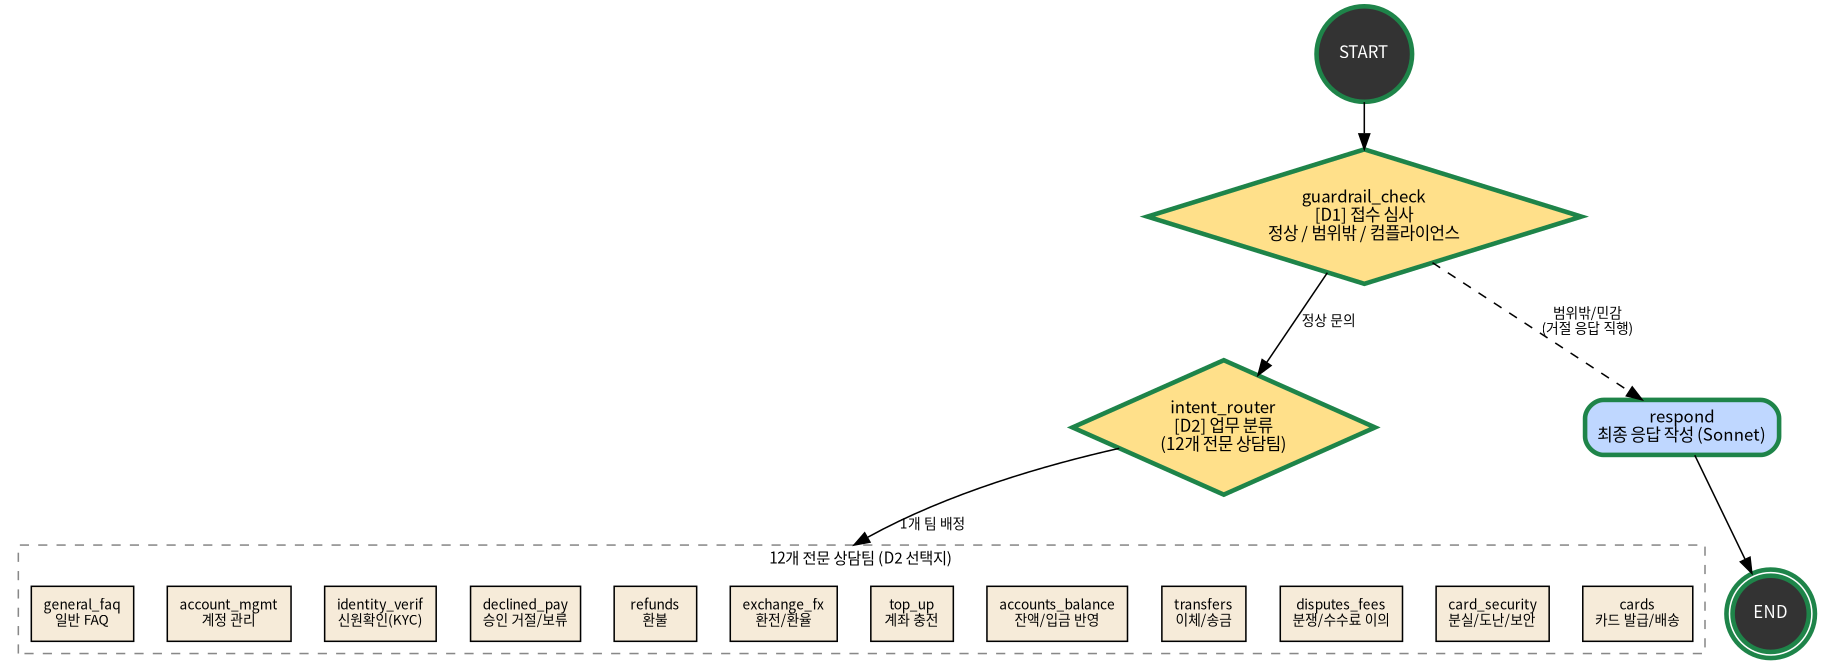

In [6]:
W.draw_build_stage(1)

## 5. Recursive loop 1 — clarification

고객 문의가 모호하면 agent가 **되묻고**, 답을 받은 뒤 **다시 판정**합니다.

```
clarify_gate [D5] --need_clarification--> ask_clarify --(loop)--> clarify_gate
             └--info_sufficient / 상한 도달--> tool_step
```

- `clarify_gate`는 **대화 전체**를 보고 D5를 판정합니다 (loop를 돌수록 대화가 길어짐)
- `ask_clarify`에서 질문은 Sonnet이 생성하고, 고객 답변은 실습 재현성을 위해 script가 제공합니다
- 상한(2회) 도달 시 강제로 진행합니다 — loop 안전장치
> **금융 업무 관점**: 상담원이 "어느 카드인지, 언제 거래인지"를 되묻는 **정보 보완 절차**입니다. 분쟁 접수나 사고 신고는 거래 특정(일시·금액·가맹점) 없이는 접수가 불가하므로, 실제 업무에서도 필수 반복 단계입니다.


In [7]:
def clarify_gate(state: AgentState):
    dr = decision.decide(state_text="Conversation so far:\n" + conv_text(state),
                         question=D5_QUESTION, choices=D5_CHOICES, decision_id="d5")
    return {"d5_labels": [dr.label], "trace": [dec_event("clarify_gate", "d5", dr, decision.name)]}

def route_clarify(state: AgentState):
    if (state["d5_labels"][-1] == "need_clarification"
            and state.get("clarify_asks", 0) < MAX_CLARIFY_ASKS):
        return "ask_clarify"
    return "tool_step"

def ask_clarify(state: AgentState):
    lr = llm.generate(system=ASK_CLARIFY_SYSTEM,
                      user="Conversation so far:\n" + conv_text(state), max_tokens=120)
    asks = state.get("clarify_asks", 0)
    s = state["script"]
    reply = s["clarify_reply"] if (s.get("vague") and asks == 0) else s["no_info_reply"]
    return {"clarify_asks": asks + 1,
            "dialogue": [{"role": "agent", "text": lr.text},
                         {"role": "customer", "text": reply}],
            "trace": [llm_event("ask_clarify", lr, llm.name)]}

print("nodes: clarify_gate, ask_clarify (+route_clarify)")

nodes: clarify_gate, ask_clarify (+route_clarify)


**지금까지의 그래프** — 업무 분류 뒤에 **첫 번째 recursive loop**(빨간 edge)가 생겼습니다. 정보가 부족하면 되묻고, 답변을 받아 다시 판정합니다.

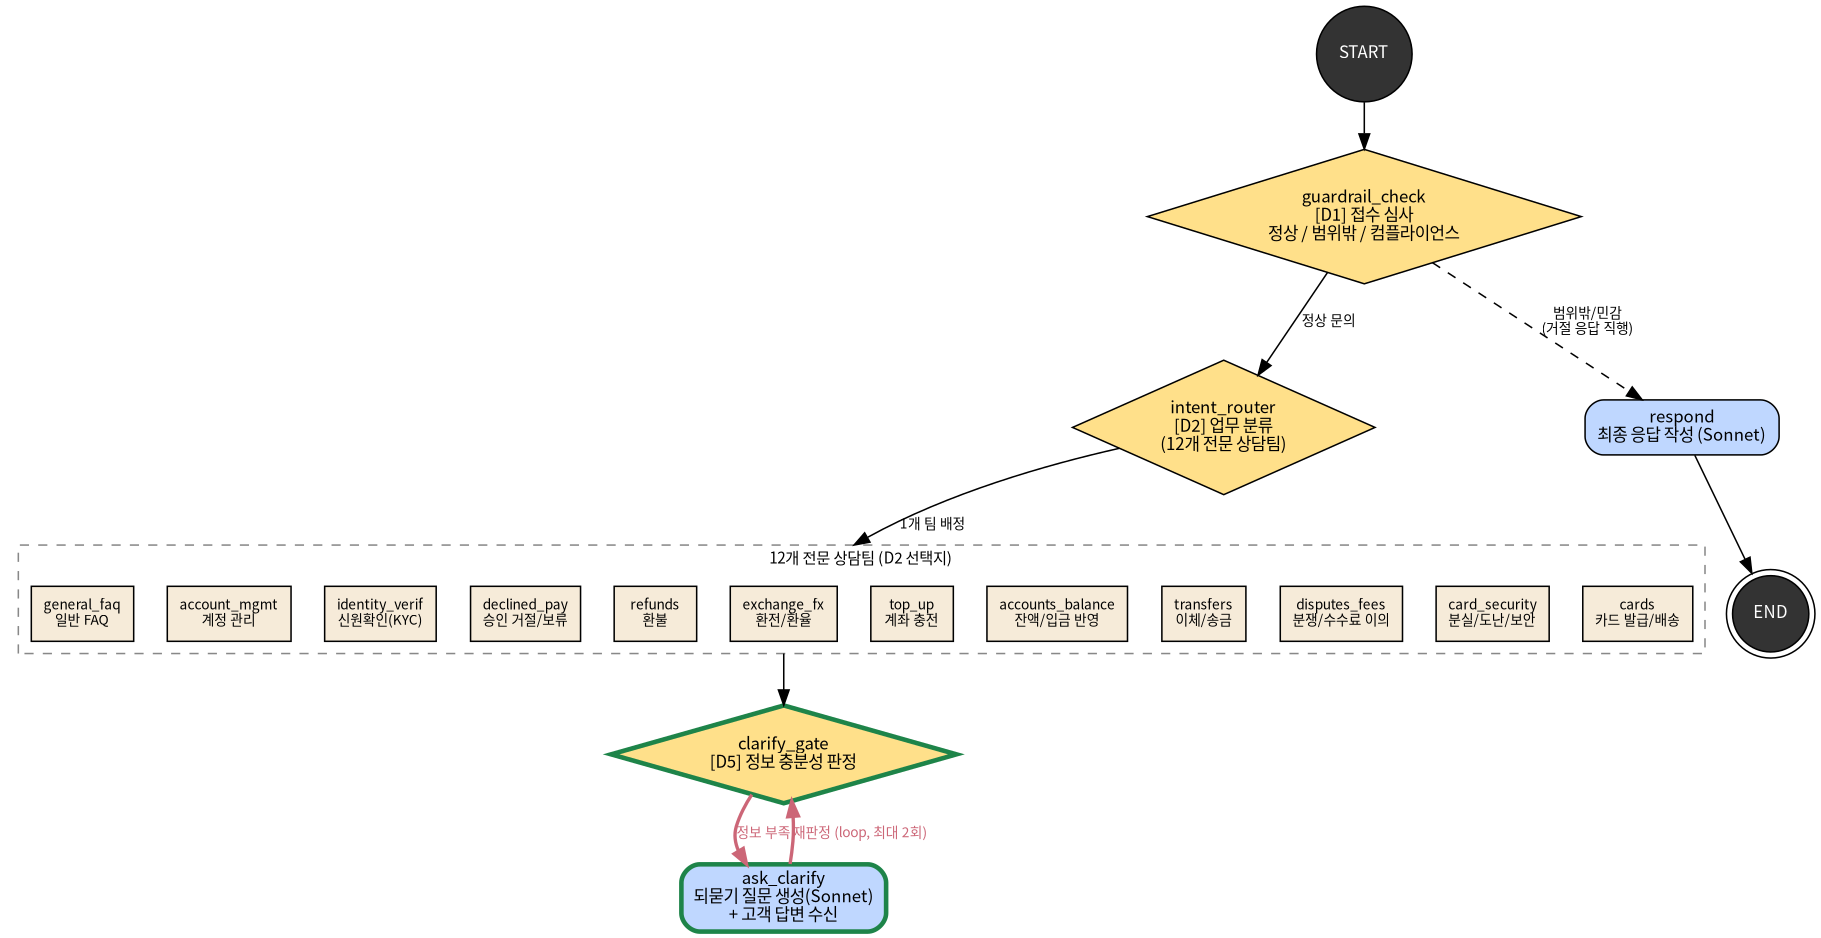

In [8]:
W.draw_build_stage(2)

## 6. Recursive loop 2 — tool 선택·실행·재시도

`tool_step` 하나가 세 가지 일을 합니다: **D3** category 전담 tool 중 선택(이미 써본 tool 제외) → tool 실행 → **D6** 결과 검토.

```
tool_step [D3+tool+D6] --try_alternative--> tool_step   (다른 tool로 재시도)
         ├--goal_met--> summarize
         └--give_up--> escalation_gate                   (상담사 이관 경로)
```

실습에서는 tool이 script에 따라 success / tool_error / blocked를 반환합니다 — D6 정답이 객관적으로 정해지는 구조입니다.
> **금융 업무 관점**: tool 호출은 **코어뱅킹/카드원장/대외계 시스템 거래**에 해당합니다. 운영계 시스템은 일시 오류가 일상이므로 '오류 코드를 읽고 대체 거래로 재시도, 안 되면 수작업 이관'이라는 장애 대응 절차가 있고, D6 loop가 그것을 재현합니다.


In [9]:
def tool_step(state: AgentState):
    category = state["d2"]
    attempt = state.get("tool_attempts", 0)
    used = state.get("tools_used", [])
    choices = [t for t in CATEGORY_TOOLS[category] if t not in used]
    events = []
    if len(choices) == 1:   # 남은 후보가 1개면 자동 선택 (판단 불필요)
        tool = choices[0]
        events.append({"node": "tool_select", "kind": "auto", "decision": "d3",
                       "label": tool, "latency_ms": 0.0, "cost_usd": 0.0})
    else:
        dr = decision.decide(
            state_text="Conversation so far:\n" + conv_text(state)
                       + (f"\n\nAlready tried (failed): {', '.join(used)}" if used else ""),
            question=D3_QUESTION.format(category=category), choices=choices, decision_id="d3")
        tool = dr.label
        events.append(dec_event("tool_select", "d3", dr, decision.name))
    t0 = time.perf_counter()
    tool_result = run_tool_v2(tool, state["conv_id"], state["script"], attempt)
    events.append(tool_event(f"tool:{tool}", t0))
    dr6 = decision.decide(
        state_text=(f"Customer request:\n{state['dialogue'][0]['text']}\n\n"
                    f"Tool executed: {tool}\nTool result:\n"
                    f"{json.dumps(tool_result, ensure_ascii=False)}"),
        question=D6_QUESTION, choices=D6_CHOICES, decision_id="d6")
    events.append(dec_event("tool_review", "d6", dr6, decision.name))
    return {"d3_labels": [tool], "d6_labels": [dr6.label], "tools_used": [tool],
            "tool_attempts": attempt + 1, "tool_result": tool_result, "trace": events}

def route_tool(state: AgentState):
    label = state["d6_labels"][-1]
    remaining = [t for t in CATEGORY_TOOLS[state["d2"]]
                 if t not in state.get("tools_used", [])]
    if (label == "try_alternative"
            and state.get("tool_attempts", 0) < MAX_TOOL_ATTEMPTS and remaining):
        return "tool_step"
    if label == "goal_met":
        return "summarize"
    return "give_up"

def mark_give_up(state: AgentState):
    return {"gave_up": True}

print("nodes: tool_step, give_up (+route_tool)")

nodes: tool_step, give_up (+route_tool)


**지금까지의 그래프** — **두 번째 recursive loop**: tool 결과 검토(D6)가 `try_alternative`면 자기 자신으로 돌아가 다른 tool로 재시도합니다. `give_up`이면 자동 처리를 포기하는 경로가 생겼습니다.

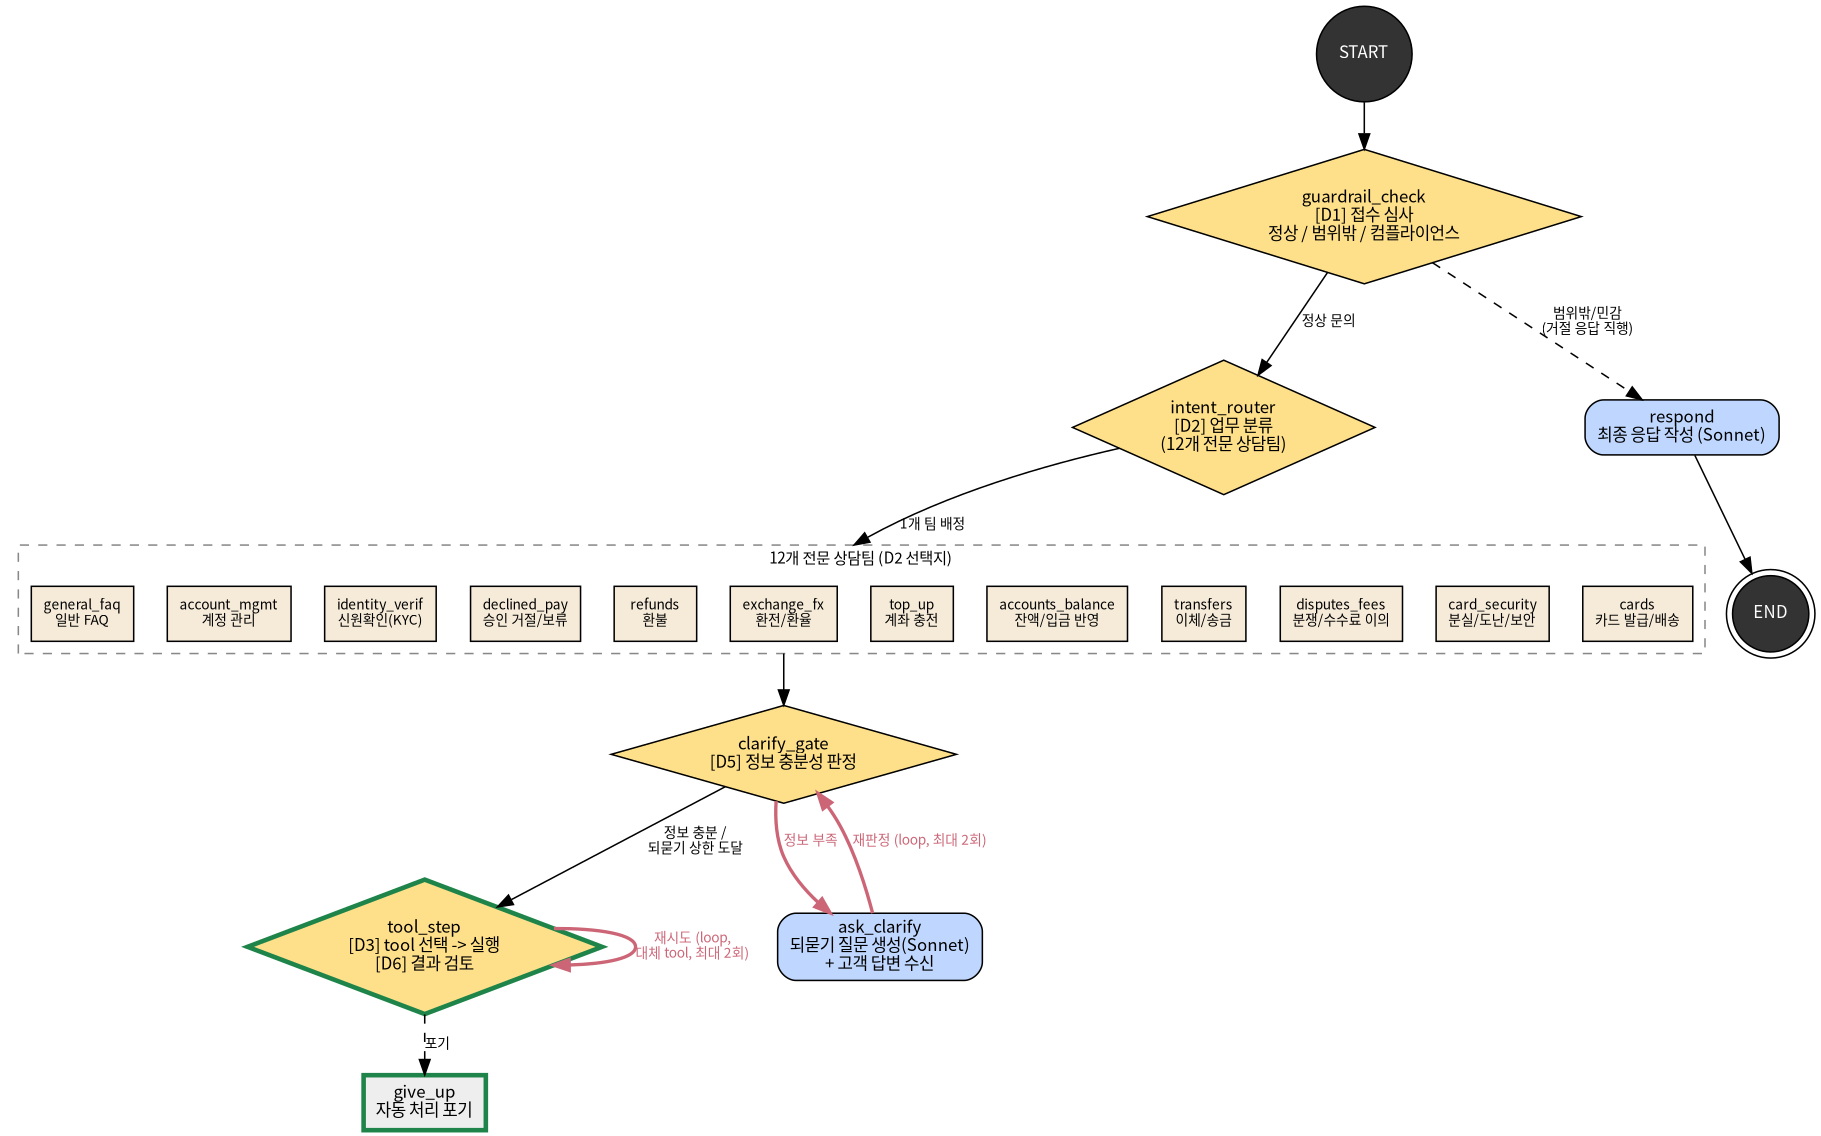

In [10]:
W.draw_build_stage(3)

## 7. 후반부 노드: 요약, 리스크 점검(D7), KYC(D8), 처리 방침(D4), 최종 응답

- **summarize**: Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리 (생성)
- **risk_check [D7]**: tool 결과에 fraud/AML 모니터링 flag가 있으면 KYC 재검증으로 분기
- **kyc_verify**: KYC tool 실행 + **D8** 통과 여부 판정
- **escalation_gate [D4]**: resolve / clarify / human_handoff 결정
- **respond**: Sonnet이 결정된 방침대로 최종 한국어 응답 작성 (생성)
> **금융 업무 관점**: summarize는 **상담 처리 메모**(후속 상담원·민원 대응을 위한 이력 기록), D7은 **FDS(이상거래탐지) 알림 확인**, kyc_verify는 **고객확인 재이행(KYC/CDD)** — 고위험 거래를 재검증 없이 종결하면 안 되는 규정의 코드화입니다. D4는 **전결권 판단**(자동 종결 가능 vs 권한 밖이라 상담사 이관), respond는 **고객 안내문 작성**(민원 예방을 위한 표준 화법)입니다.


In [11]:
def summarize(state: AgentState):
    lr = llm.generate(
        system=SPECIALIST_SYSTEM.format(category=state["d2"]),
        user=(f"Conversation:\n{conv_text(state)}\n\n"
              f"Tool executed: {state['tool_result']['tool']}\nTool result:\n"
              f"{json.dumps(state['tool_result'], ensure_ascii=False)}"), max_tokens=300)
    return {"specialist_summary": lr.text, "trace": [llm_event("summarize", lr, llm.name)]}

def risk_check(state: AgentState):
    ctx = (f"Case facts:\n{state.get('specialist_summary', '')}\n\n"
           f"Tool result:\n{json.dumps(state.get('tool_result'), ensure_ascii=False)}")
    dr = decision.decide(state_text=ctx, question=D7_QUESTION,
                         choices=D7_CHOICES, decision_id="d7")
    return {"d7": dr.label, "trace": [dec_event("risk_check", "d7", dr, decision.name)]}

def kyc_verify(state: AgentState):
    t0 = time.perf_counter()
    kyc = run_kyc(state["conv_id"], state["script"])
    events = [tool_event("tool:run_kyc_check", t0)]
    dr = decision.decide(state_text=f"KYC result:\n{json.dumps(kyc, ensure_ascii=False)}",
                         question=D8_QUESTION, choices=D8_CHOICES, decision_id="d8")
    events.append(dec_event("kyc_review", "d8", dr, decision.name))
    return {"d8": dr.label, "kyc_result": kyc, "trace": events}

def escalation_gate(state: AgentState):
    parts = [f"Conversation:\n{conv_text(state)}",
             f"Tool result:\n{json.dumps(state.get('tool_result'), ensure_ascii=False)}"]
    if state.get("specialist_summary"):
        parts.append(f"Specialist facts:\n{state['specialist_summary']}")
    if state.get("kyc_result") is not None:
        parts.append(f"KYC result:\n{json.dumps(state['kyc_result'], ensure_ascii=False)}")
    dr = decision.decide(state_text="\n\n".join(parts), question=D4_QUESTION,
                         choices=D4_CHOICES, decision_id="d4")
    return {"d4": dr.label, "trace": [dec_event("escalation_gate", "d4", dr, decision.name)]}

def respond(state: AgentState):
    action = state["d1"] if state["d1"] != "in_scope" else state.get("d4", "resolve")
    parts = [f"Decided action: {action}", f"Conversation:\n{conv_text(state)}"]
    if state.get("specialist_summary"):
        parts.append(f"Resolution facts:\n{state['specialist_summary']}")
    if state.get("tool_result"):
        parts.append(f"Tool result:\n{json.dumps(state['tool_result'], ensure_ascii=False)}")
    if state.get("kyc_result") is not None:
        parts.append(f"KYC result:\n{json.dumps(state['kyc_result'], ensure_ascii=False)}")
    lr = llm.generate(system=RESPOND_SYSTEM, user="\n\n".join(parts), max_tokens=400)
    return {"final_response": lr.text, "trace": [llm_event("respond", lr, llm.name)]}

print("nodes: summarize, risk_check, kyc_verify, escalation_gate, respond")

nodes: summarize, risk_check, kyc_verify, escalation_gate, respond


**지금까지의 그래프** — 요약, 리스크 점검(D7), 조건부 KYC sub-flow(D8)가 추가됐습니다. 이제 처리 방침(D4)과 최종 응답만 연결하면 완성입니다.

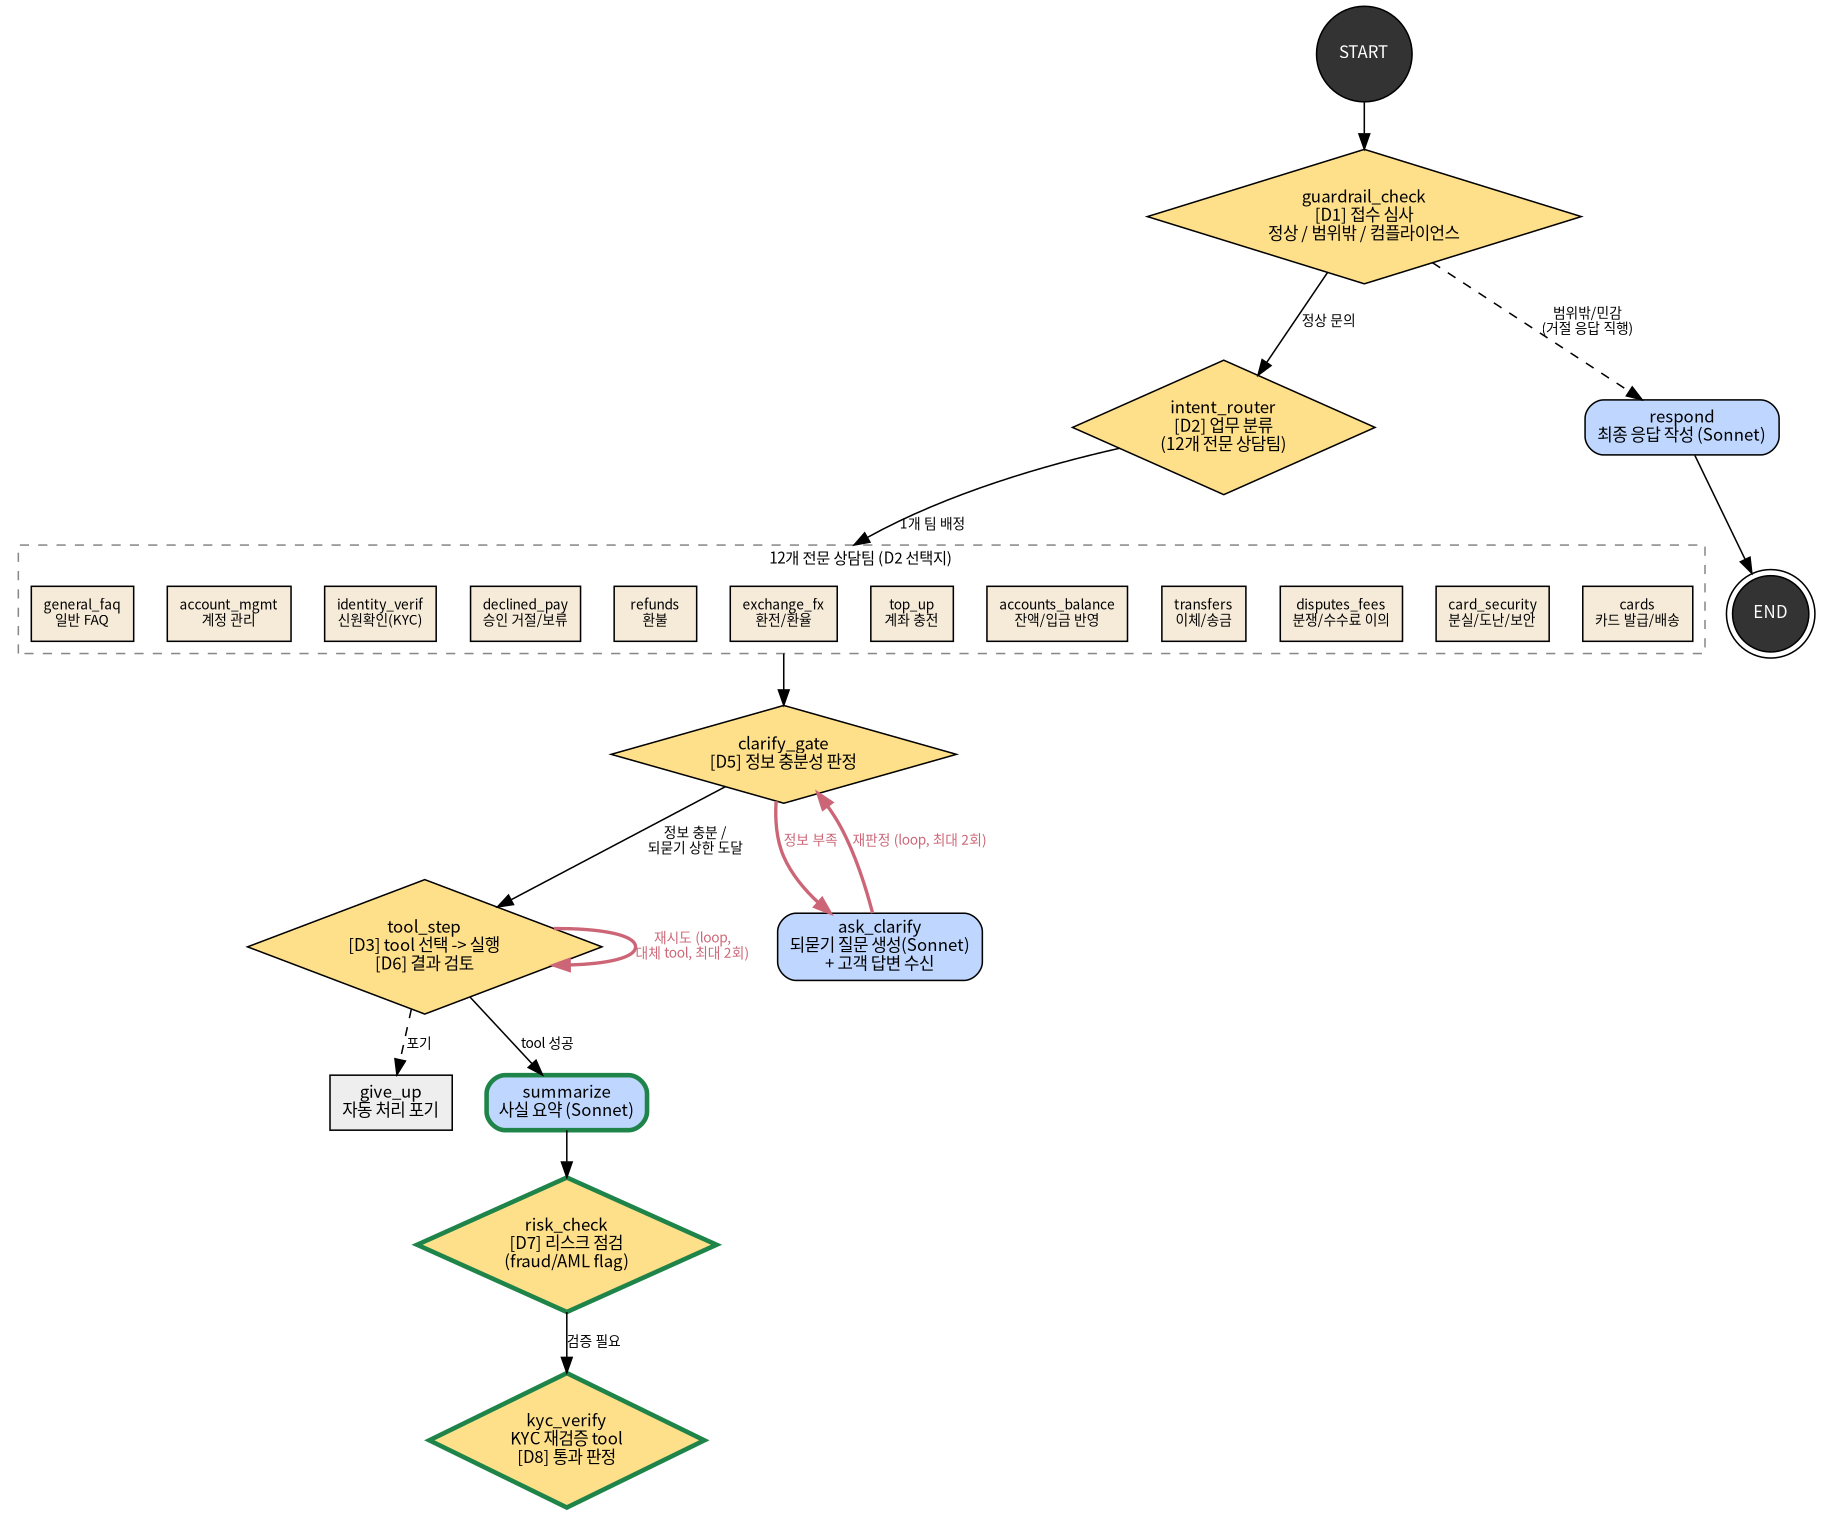

In [12]:
W.draw_build_stage(4)

## 8. 그래프 조립

노드를 등록하고 edge로 연결합니다. **conditional edge**가 분기와 recursive loop를 만듭니다.
> **금융 업무 관점**: 이 wiring은 업무 매뉴얼에 있던 **처리 흐름도(BPM)를 실행 가능한 코드로 옮기는 단계**입니다. conditional edge가 매뉴얼의 분기 규정('민감 문의는 즉시 거절 안내', 'FDS 알림 시 재검증')에 해당합니다.


In [13]:
from langgraph.graph import StateGraph, START, END

g = StateGraph(AgentState)
for name, fn in [("guardrail_check", guardrail_check), ("intent_router", intent_router),
                 ("clarify_gate", clarify_gate), ("ask_clarify", ask_clarify),
                 ("tool_step", tool_step), ("give_up", mark_give_up),
                 ("summarize", summarize), ("risk_check", risk_check),
                 ("kyc_verify", kyc_verify), ("escalation_gate", escalation_gate),
                 ("respond", respond)]:
    g.add_node(name, fn)

g.add_edge(START, "guardrail_check")
g.add_conditional_edges("guardrail_check",
    lambda s: "intent_router" if s["d1"] == "in_scope" else "respond",
    ["intent_router", "respond"])                       # 비정상 문의는 즉시 응답으로
g.add_edge("intent_router", "clarify_gate")
g.add_conditional_edges("clarify_gate", route_clarify, ["ask_clarify", "tool_step"])
g.add_edge("ask_clarify", "clarify_gate")               # <= recursive loop 1
g.add_conditional_edges("tool_step", route_tool, ["tool_step", "summarize", "give_up"])  # <= loop 2
g.add_edge("give_up", "escalation_gate")
g.add_edge("summarize", "risk_check")
g.add_conditional_edges("risk_check",
    lambda s: "kyc_verify" if s["d7"] == "needs_verification" else "escalation_gate",
    ["kyc_verify", "escalation_gate"])
g.add_edge("kyc_verify", "escalation_gate")
g.add_edge("escalation_gate", "respond")
g.add_edge("respond", END)

my_graph = g.compile()
print("compiled. nodes:", list(my_graph.get_graph().nodes))

compiled. nodes: ['__start__', 'guardrail_check', 'intent_router', 'clarify_gate', 'ask_clarify', 'tool_step', 'give_up', 'summarize', 'risk_check', 'kyc_verify', 'escalation_gate', 'respond', '__end__']


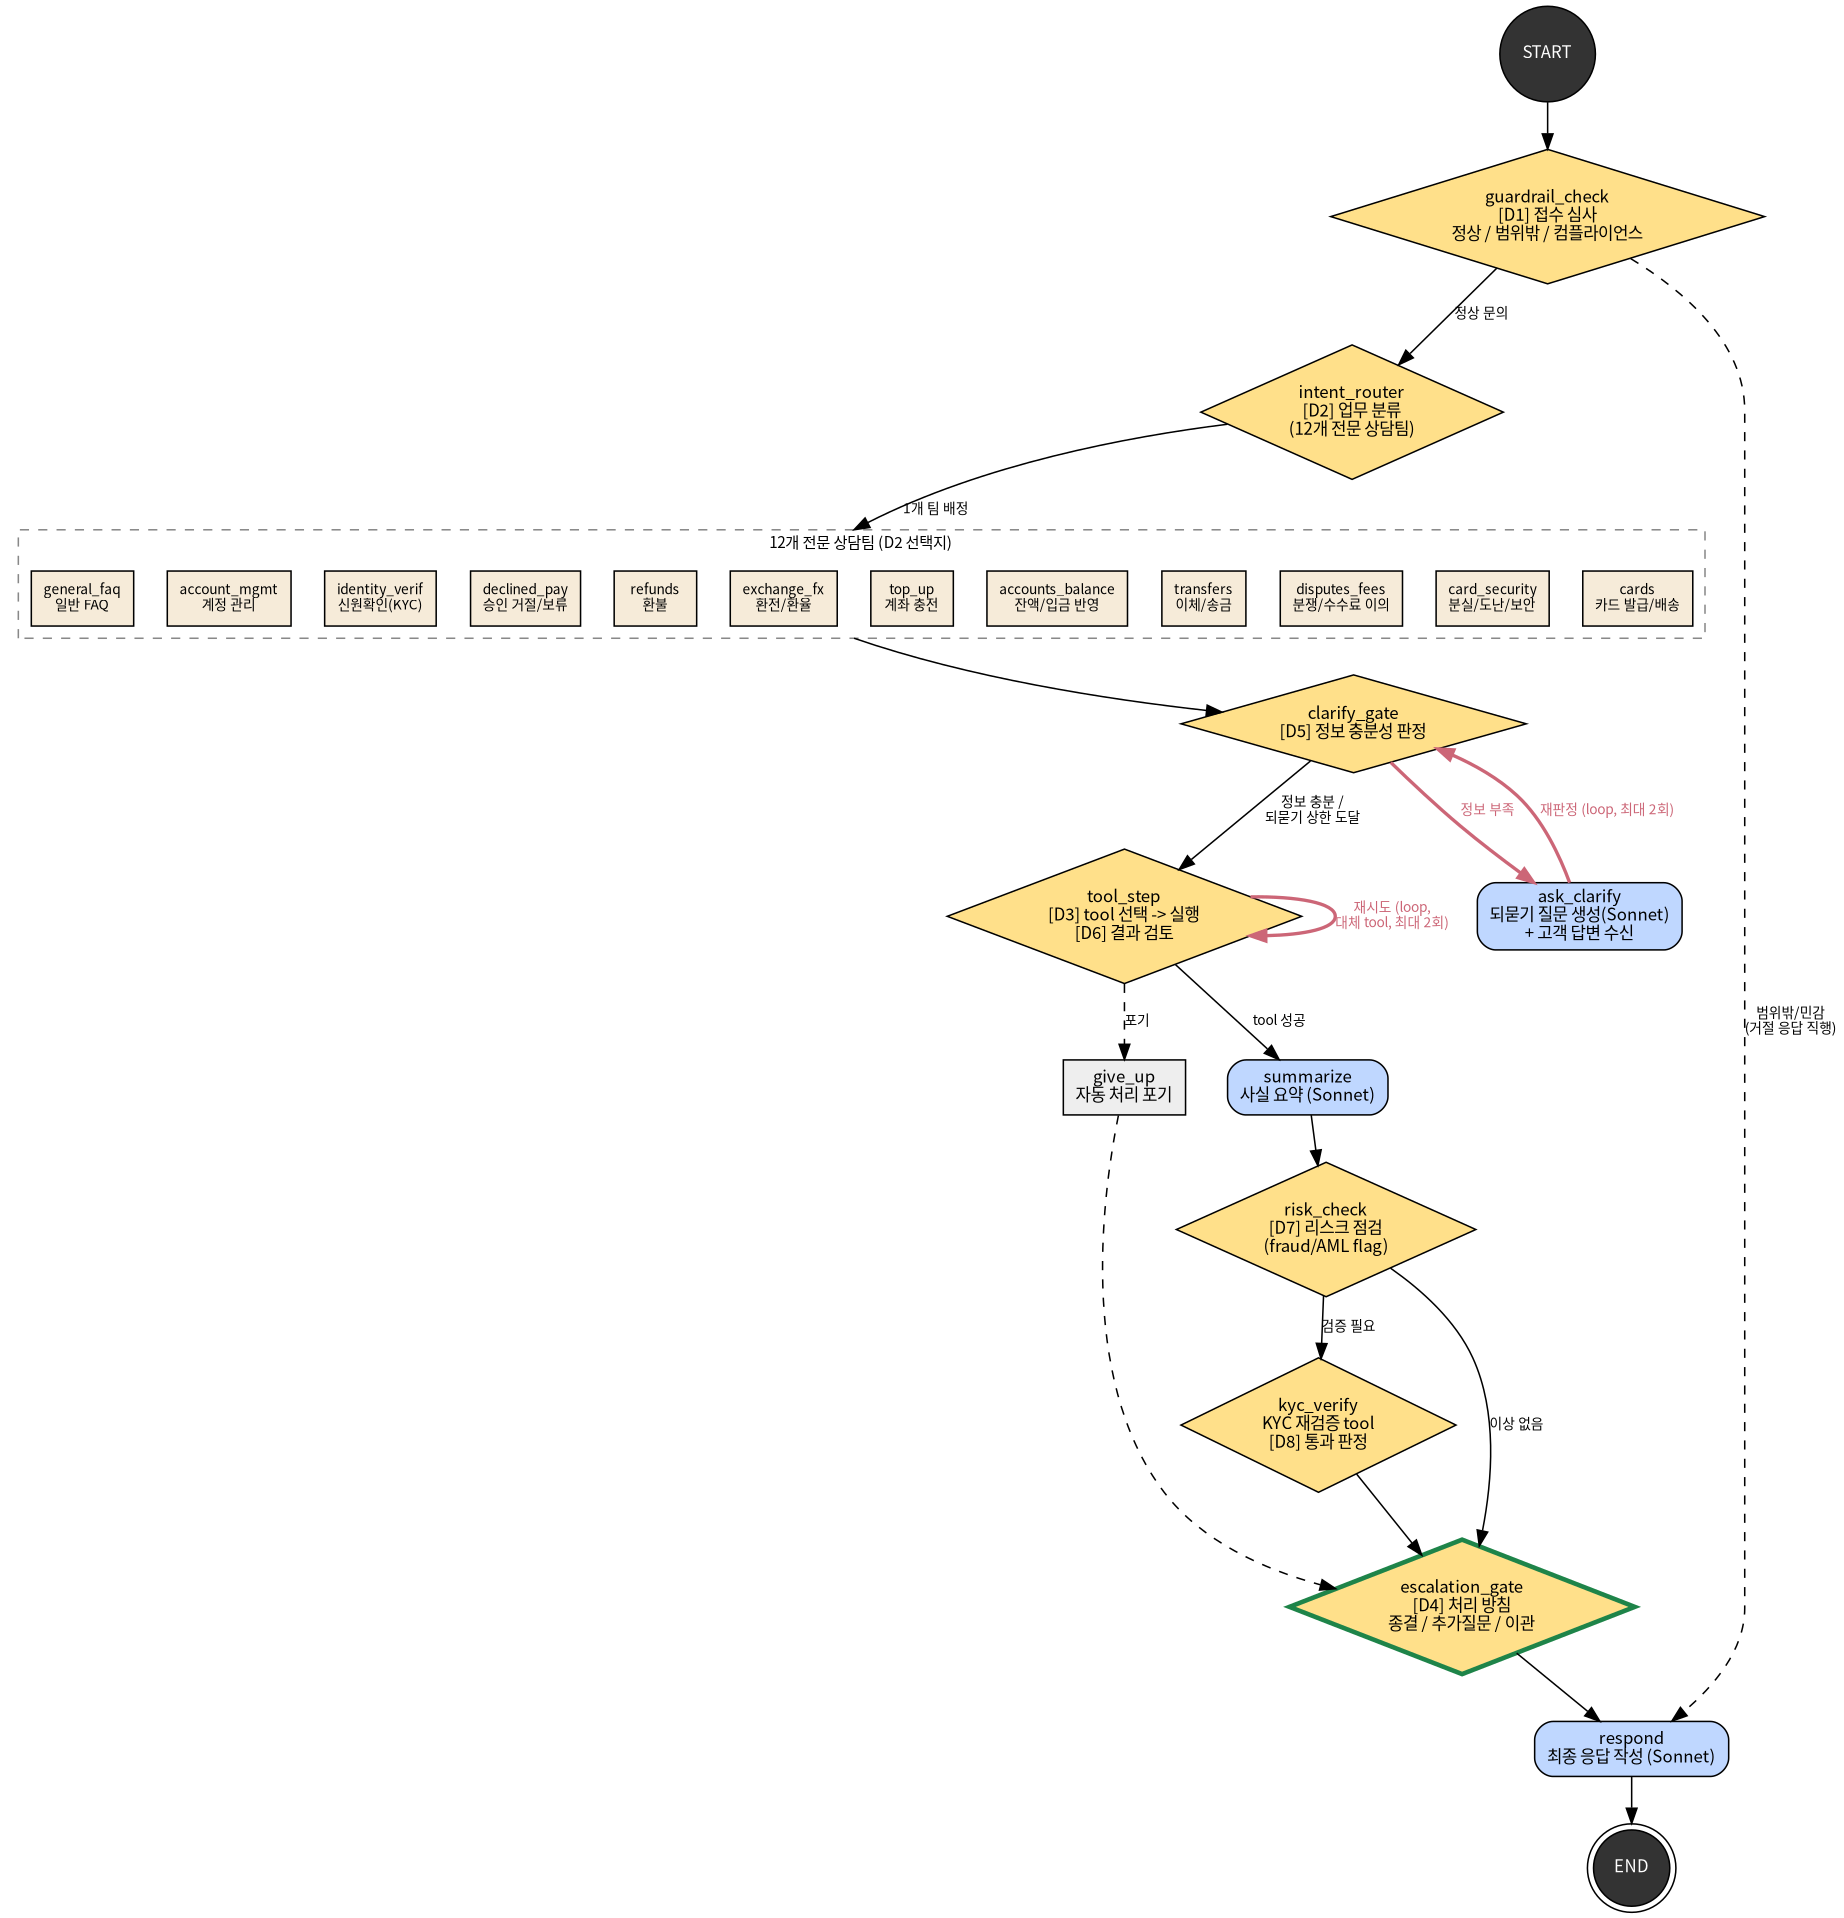

In [14]:
# 완성된 전체 그래프 (한글 캡션, 빨간 edge = recursive loop)
W.draw_build_stage(5)

## 9. 시험 구동

방금 조립한 그래프에 간단한 문의 1건을 흘려봅니다. `ws_common.run_verbose()`가 노드 실행을 스트리밍으로 받아 **STEP별로 무슨 판단/생성이 일어나는지** 출력합니다.

In [15]:

res = W.run_verbose(my_graph,
    "새 체크카드를 받았는데 활성화하고 싶어요. 카드 끝자리는 7712입니다.",
    {"vague": False, "clarify_reply": None, "no_info_reply": W.NO_INFO,
     "tool_outcomes": ["success"], "risk_flag": False, "kyc_result": None},
    "SGLang(직접 조립)")


[SGLang(직접 조립)] 고객: 새 체크카드를 받았는데 활성화하고 싶어요. 카드 끝자리는 7712입니다.



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (38ms, confidence 1.000)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (36ms, confidence 1.000)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (34ms, confidence 1.000)

STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> activate_card   (33ms, confidence 1.000)
      tool 실행: activate_card   (0.0ms)
      판정[D6] -> goal_met   (35ms, confidence 1.000)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (2,420ms)
      요약(첫 줄): Based on the tool result, here are the key resolution facts:

STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (38ms, confidence 1.000)

STEP 7 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> resolve   (36ms, confidence 1.000)



STEP 8 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (4,483ms)
      --- 최종 응답 ---
      안녕하세요,
      
      끝자리 7712 체크카드가 성공적으로 활성화되었습니다. 이제 바로 사용하실 수 있습니다.
      
      참조번호: REF-ws-SGLang(직접 조립)-27515
      
      카드를 안전하게 보관하시고, 첫 사용 시 PIN 번호를 설정해 주시기 바랍니다. 추가로 도움이 필요하시면 언제든지 연락 주세요.
      
      감사합니다.

>>> [SGLang(직접 조립)] 결정 7회 합계 251ms | 생성 6,903ms | e2e 7,162ms


## 10. 정리

- agent = **판단 노드 8종(D1-D8)** + **생성 노드 3종** + recursive loop 2개 + 조건부 KYC sub-flow
- 이 노트북에서 작성한 코드는 `agent/graph_v2.py`의 `build_graph_v2(decision, llm)`와 동일합니다. 다음 노트북(02-04)부터는 이를 import해서 **Haiku arm과 SGLang arm을 같은 topology로** 만들어 상담 예제를 비교 실행합니다.
- `decision = haiku_dec`로 바꿔 이 노트북을 다시 실행하면 같은 그래프가 Haiku 판단으로 돕니다 — 직접 비교해 보세요.